# Student Performance Prediction Using Machine Learning

**Stage 1: Data loading, exploratory data analysis (EDA) and a baseline model**

**Dataset:** [Student Performance (UCI Machine Learning Repository)](https://archive.ics.uci.edu/dataset/320/student+performance)
Data from two Portuguese secondary schools, collected from school reports and questionnaires.
It contains two subjects: Mathematics (`student-mat.csv`) and Portuguese language (`student-por.csv`).

**Goal:** predict whether a student will pass the final exam (final grade `G3 >= 10` on a 0-20 scale).

**Plan:**
1. Load the data
2. Inspect structure and missing values
3. Exploratory data analysis (4 plots)
4. Baseline model: Logistic Regression

## 1. Imports and settings

In [ ]:
import os
import glob
import urllib.request
import zipfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

## 2. Load the dataset

The cell below downloads the dataset from UCI (if it is not already in the `data/` folder) and unpacks it.
If you are offline, download the archive manually from the link above and put the `.csv` files into `data/`.

In [ ]:
DATA_DIR = "../data"
URL = "https://archive.ics.uci.edu/static/public/320/student+performance.zip"
os.makedirs(DATA_DIR, exist_ok=True)

def find_csv(name):
    hits = glob.glob(os.path.join(DATA_DIR, "**", name), recursive=True)
    return hits[0] if hits else None

if find_csv("student-mat.csv") is None:
    zip_path = os.path.join(DATA_DIR, "student_performance.zip")
    print("Downloading dataset...")
    urllib.request.urlretrieve(URL, zip_path)
    with zipfile.ZipFile(zip_path) as z:
        z.extractall(DATA_DIR)
    # the archive may contain a nested zip file
    for nested in glob.glob(os.path.join(DATA_DIR, "**", "*.zip"), recursive=True):
        if nested != zip_path:
            with zipfile.ZipFile(nested) as z:
                z.extractall(DATA_DIR)

mat_path = find_csv("student-mat.csv")
print("Found:", mat_path)

# The files are semicolon-separated
df = pd.read_csv(mat_path, sep=";")
df.head()

Found: ../data/student-mat.csv


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


We use the **Mathematics** dataset (395 students). The Portuguese dataset has the same structure
and can be used in the same way later.

## 3. Data structure and missing values

In [ ]:
print("Shape:", df.shape)
print()
df.info()

Shape: (395, 33)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      395 non-null    object
 1   sex         395 non-null    object
 2   age         395 non-null    int64 
 3   address     395 non-null    object
 4   famsize     395 non-null    object
 5   Pstatus     395 non-null    object
 6   Medu        395 non-null    int64 
 7   Fedu        395 non-null    int64 
 8   Mjob        395 non-null    object
 9   Fjob        395 non-null    object
 10  reason      395 non-null    object
 11  guardian    395 non-null    object
 12  traveltime  395 non-null    int64 
 13  studytime   395 non-null    int64 
 14  failures    395 non-null    int64 
 15  schoolsup   395 non-null    object
 16  famsup      395 non-null    object
 17  paid        395 non-null    object
 18  activities  395 non-null    object
 19  nursery     395 non-null    obje

In [ ]:
# Missing values and duplicates
missing = df.isnull().sum()
print("Total missing values:", missing.sum())
print("Duplicated rows:", df.duplicated().sum())
missing[missing > 0]

Total missing values: 0
Duplicated rows: 0


,0


In [ ]:
# Summary statistics for numeric columns
df.describe().T

,count,mean,std,min,25%,50%,75%,max
age,395.0,16.696203,1.276043,15.0,16.0,17.0,18.0,22.0
Medu,395.0,2.749367,1.094735,0.0,2.0,3.0,4.0,4.0
Fedu,395.0,2.521519,1.088201,0.0,2.0,2.0,3.0,4.0
traveltime,395.0,1.448101,0.697505,1.0,1.0,1.0,2.0,4.0
studytime,395.0,2.035443,0.839240,1.0,1.0,2.0,2.0,4.0
failures,395.0,0.334177,0.743651,0.0,0.0,0.0,0.0,3.0
famrel,395.0,3.944304,0.896659,1.0,4.0,4.0,5.0,5.0
freetime,395.0,3.235443,0.998862,1.0,3.0,3.0,4.0,5.0
goout,395.0,3.108861,1.113278,1.0,2.0,3.0,4.0,5.0
Dalc,395.0,1.481013,0.890741,1.0,1.0,1.0,2.0,5.0


In [ ]:
# Categorical columns and their unique values
cat_cols = df.select_dtypes(include="object").columns.tolist()
for c in cat_cols:
    print(f"{c:12s} -> {sorted(df[c].unique())}")

school       -> ['GP', 'MS']
sex          -> ['F', 'M']
address      -> ['R', 'U']
famsize      -> ['GT3', 'LE3']
Pstatus      -> ['A', 'T']
Mjob         -> ['at_home', 'health', 'other', 'services', 'teacher']
Fjob         -> ['at_home', 'health', 'other', 'services', 'teacher']
reason       -> ['course', 'home', 'other', 'reputation']
guardian     -> ['father', 'mother', 'other']
schoolsup    -> ['no', 'yes']
famsup       -> ['no', 'yes']
paid         -> ['no', 'yes']
activities   -> ['no', 'yes']
nursery      -> ['no', 'yes']
higher       -> ['no', 'yes']
internet     -> ['no', 'yes']
romantic     -> ['no', 'yes']


### Main variables

| Group | Columns |
|---|---|
| Demographics | `school`, `sex`, `age`, `address`, `famsize`, `Pstatus` |
| Family | `Medu`, `Fedu` (parents' education), `Mjob`, `Fjob`, `guardian`, `famrel` |
| Study habits | `traveltime`, `studytime`, `failures`, `schoolsup`, `famsup`, `paid`, `activities`, `higher` |
| Lifestyle | `freetime`, `goout`, `Dalc`, `Walc`, `health`, `romantic`, `internet` |
| Attendance | `absences` |
| Grades | `G1` (1st period), `G2` (2nd period), `G3` (final, **target**) |

## 4. Target variable

The final grade `G3` ranges from 0 to 20. We convert it to a binary target:
**pass = 1 if `G3 >= 10`, otherwise 0.**

In [ ]:
df["pass"] = (df["G3"] >= 10).astype(int)

print(df["pass"].value_counts())
print()
print(df["pass"].value_counts(normalize=True).round(3))

pass
1    265
0    130
Name: count, dtype: int64

pass
1    0.671
0    0.329
Name: proportion, dtype: float64


## 5. Exploratory Data Analysis

### Plot 1: Distribution of final grades

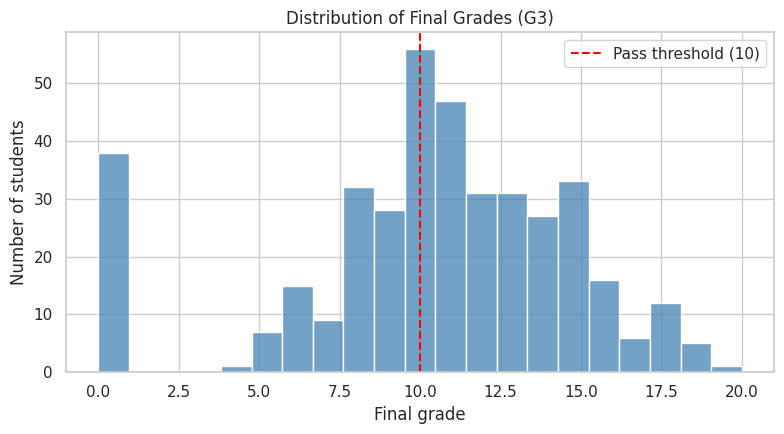

In [ ]:
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.histplot(df["G3"], bins=21, kde=False, ax=ax, color="steelblue")
ax.axvline(10, color="red", linestyle="--", label="Pass threshold (10)")
ax.set_title("Distribution of Final Grades (G3)")
ax.set_xlabel("Final grade")
ax.set_ylabel("Number of students")
ax.legend()
plt.tight_layout()
plt.show()

**Observation:** most grades are between 8 and 15. There is a noticeable group of students with a grade of 0
(they most likely did not take the final exam or dropped out).

### Plot 2: Correlation heatmap of numeric features

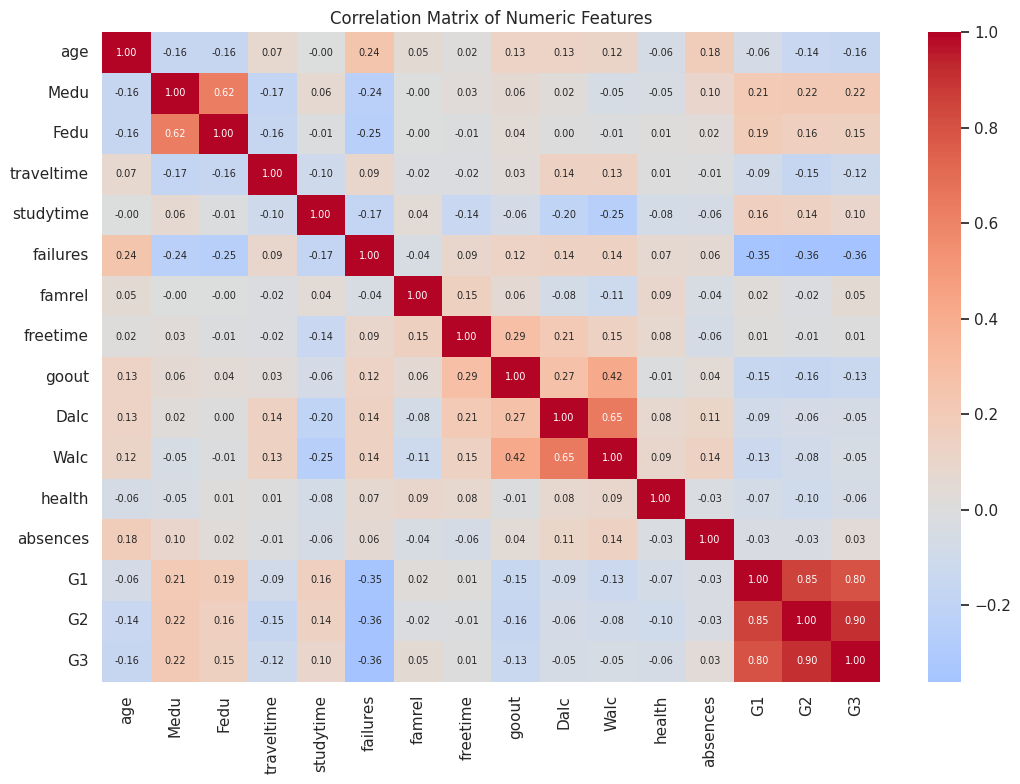

Correlation with G3:
G2            0.905
G1            0.801
Medu          0.217
Fedu          0.152
studytime     0.098
famrel        0.051
absences      0.034
freetime      0.011
Walc         -0.052
Dalc         -0.055
health       -0.061
traveltime   -0.117
goout        -0.133
age          -0.162
failures     -0.360
Name: G3, dtype: float64


In [ ]:
num_cols = df.select_dtypes(include=np.number).columns.drop("pass")
corr = df[num_cols].corr()

fig, ax = plt.subplots(figsize=(11, 8))
sns.heatmap(corr, cmap="coolwarm", center=0, annot=True, fmt=".2f",
            annot_kws={"size": 7}, ax=ax)
ax.set_title("Correlation Matrix of Numeric Features")
plt.tight_layout()
plt.show()

print("Correlation with G3:")
print(corr["G3"].drop("G3").sort_values(ascending=False).round(3))

**Observation:** `G1` and `G2` are very strongly correlated with `G3`. Among other variables,
`failures` has the strongest negative correlation, and parents' education (`Medu`, `Fedu`) has a weak positive one.

### Plot 3: Past failures and study time vs. pass rate

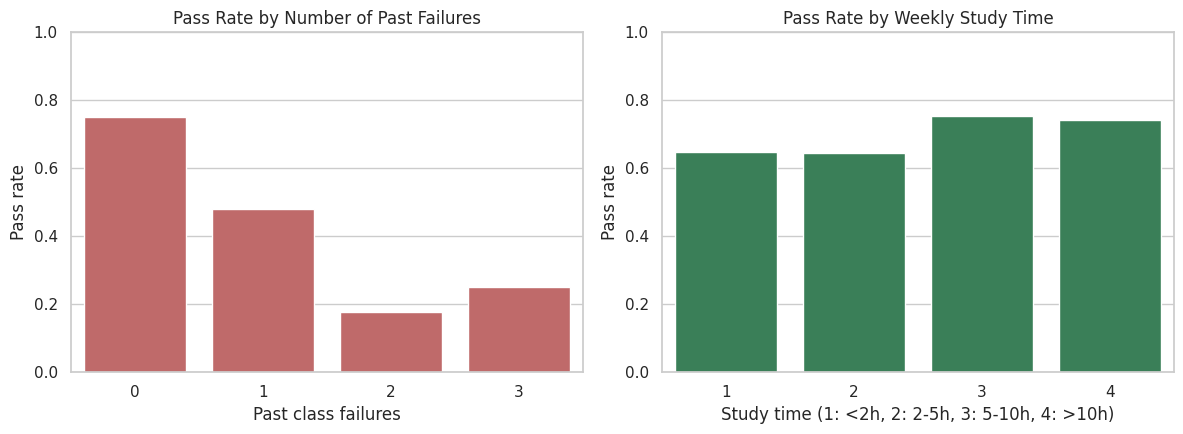

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

sns.barplot(data=df, x="failures", y="pass", errorbar=None, color="indianred", ax=axes[0])
axes[0].set_title("Pass Rate by Number of Past Failures")
axes[0].set_xlabel("Past class failures")
axes[0].set_ylabel("Pass rate")
axes[0].set_ylim(0, 1)

sns.barplot(data=df, x="studytime", y="pass", errorbar=None, color="seagreen", ax=axes[1])
axes[1].set_title("Pass Rate by Weekly Study Time")
axes[1].set_xlabel("Study time (1: <2h, 2: 2-5h, 3: 5-10h, 4: >10h)")
axes[1].set_ylabel("Pass rate")
axes[1].set_ylim(0, 1)

plt.tight_layout()
plt.show()

**Observation:** the pass rate drops sharply for students with previous failures, and tends to increase
with more weekly study time.

### Plot 4: First-period grade (G1) vs. final grade (G3)

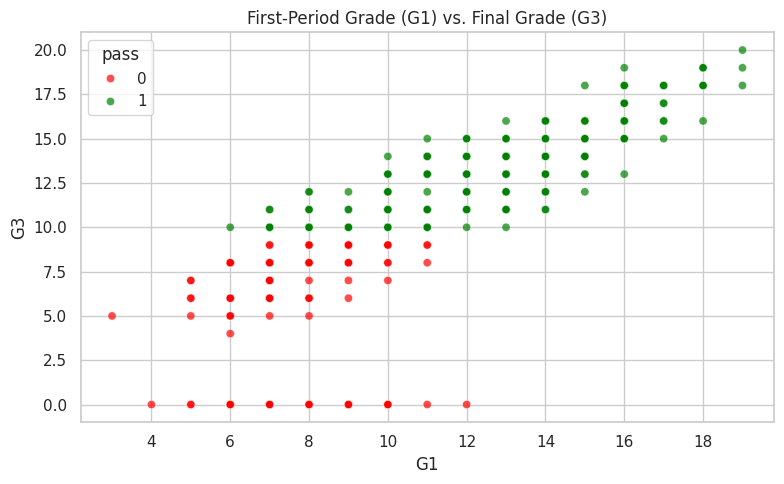

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.scatterplot(data=df, x="G1", y="G3", hue="pass", palette={0: "red", 1: "green"},
                alpha=0.7, ax=ax)
ax.set_title("First-Period Grade (G1) vs. Final Grade (G3)")
ax.set_xlabel("G1")
ax.set_ylabel("G3")
plt.tight_layout()
plt.show()

**Observation:** the relationship is almost linear: students who do well in the first period usually do well
at the end. This means `G1`/`G2` are very strong predictors, but they are also "earlier grades",
so a model using them answers "who will fail *given previous grades*?", which is less useful for early intervention.
We therefore compare two settings below.

## 6. Baseline model: Logistic Regression

We build two versions:
- **Model A:** all features, including `G1` and `G2`
- **Model B:** without `G1` and `G2` (only background and behavioral features), a harder but more realistic task

Model A: all features (with G1, G2)
Accuracy: 0.886

              precision    recall  f1-score   support

        Fail       0.77      0.92      0.84        26
        Pass       0.96      0.87      0.91        53

    accuracy                           0.89        79
   macro avg       0.87      0.90      0.88        79
weighted avg       0.90      0.89      0.89        79



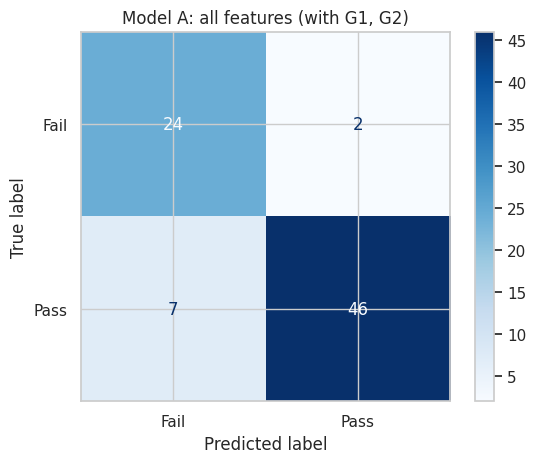

In [ ]:
def build_and_evaluate(drop_cols, title):
    X = df.drop(columns=["G3", "pass"] + drop_cols)
    y = df["pass"]

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
    )

    cat = X.select_dtypes(include="object").columns.tolist()
    num = X.select_dtypes(include=np.number).columns.tolist()

    preprocess = ColumnTransformer([
        ("num", StandardScaler(), num),
        ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), cat),
    ])

    model = Pipeline([
        ("prep", preprocess),
        ("clf", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
    ])
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    print("=" * 60)
    print(title)
    print("=" * 60)
    print(f"Accuracy: {accuracy_score(y_test, y_pred):.3f}\n")
    print(classification_report(y_test, y_pred, target_names=["Fail", "Pass"]))

    ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred),
                           display_labels=["Fail", "Pass"]).plot(cmap="Blues")
    plt.title(title)
    plt.show()
    return model

model_a = build_and_evaluate([], "Model A: all features (with G1, G2)")

Model B: without G1 and G2
Accuracy: 0.658

              precision    recall  f1-score   support

        Fail       0.47      0.35      0.40        26
        Pass       0.72      0.81      0.76        53

    accuracy                           0.66        79
   macro avg       0.60      0.58      0.58        79
weighted avg       0.64      0.66      0.64        79



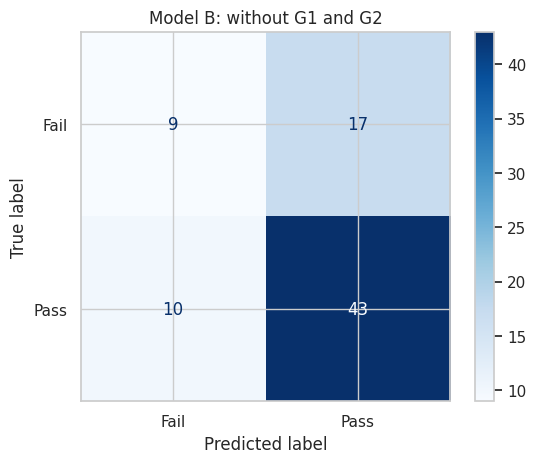

In [ ]:
model_b = build_and_evaluate(["G1", "G2"], "Model B: without G1 and G2")

### Most influential features (Model A)

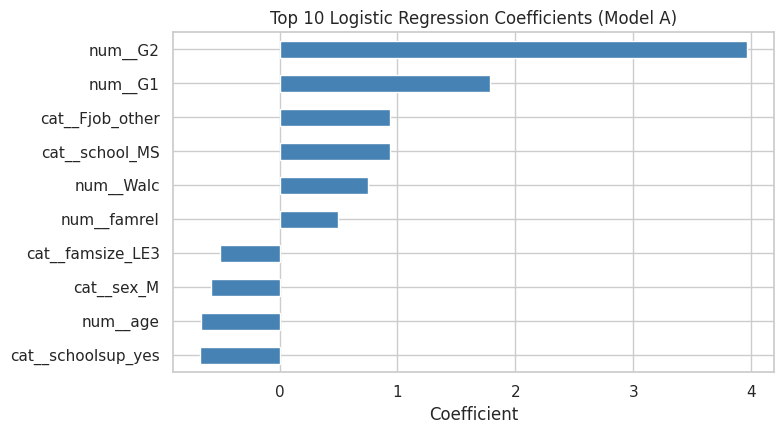

In [ ]:
feature_names = model_a.named_steps["prep"].get_feature_names_out()
coefs = pd.Series(model_a.named_steps["clf"].coef_[0], index=feature_names)
top = coefs.reindex(coefs.abs().sort_values(ascending=False).index).head(10)

fig, ax = plt.subplots(figsize=(8, 4.5))
top.sort_values().plot(kind="barh", color="steelblue", ax=ax)
ax.set_title("Top 10 Logistic Regression Coefficients (Model A)")
ax.set_xlabel("Coefficient")
plt.tight_layout()
plt.show()

## 7. Conclusion

- The dataset is clean: no missing values, 395 students, 33 columns.
- About two thirds of students pass the final exam, so the classes are moderately imbalanced.
- The strongest predictors are the earlier grades `G1` and `G2`; `failures`, `absences` and `studytime` also matter.
- Logistic Regression is a good, interpretable baseline. Without `G1`/`G2` the accuracy drops noticeably,
  which shows how much of the prediction power comes from earlier grades.